# **Algoritmo de clasificación**

En el notebook anterior (`segmentation_algorithm.ipynb`) ya abarcamos el tema de como se trataran las imagenes una vez lleguen al microservicio de Inteligencia Artificial en cunato a la tarea de segmentación para obtener un fotograma en el que logremos encuadrar netamente la imagen de la fruta.

En este notebook abordamos el siguiente paso del pipeline: tomar ese recorte de la fruta y determinar su estado de calidad. Para ello entrenaremos un modelo de clasificación de imágenes capaz de distinguir entre las tres clases definidas para Agrotrace: **fresca** (`fresh`), **calidad regular** (`mild`) y **podrida** (`rotten`).

Como datos de entrenamiento usaremos el dataset que construimos en `fruit_dataset.ipynb` y que publicamos en Hugging Face ([Juanxxo/agrotrace](https://huggingface.co/datasets/Juanxxo/agrotrace)). Como sus imágenes también pasaron por el recorte con YOLO, el modelo aprende sobre el mismo tipo de entrada que recibirá en producción: la fruta aislada, sin el fondo.

A lo largo del notebook cargaremos y prepararemos los datos, entrenaremos el modelo, evaluaremos su desempeño por clase y lo exportaremos para integrarlo en el microservicio de Inteligencia Artificial.

In [1]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())

2.8.0+cu128
True


In [2]:
!nvidia-smi

Fri Oct 23 14:01:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.91.07              Driver Version: 595.91.07      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-80GB          On  |   00000000:BD:00.0 Off |                    0 |
| N/A   35C    P0             65W /  400W |       4MiB /  81920MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
%pip install "tensorflow[and-cuda]" huggingface_hub matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 89.3 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 102.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 94.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 96.7 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 MB 95.5 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 855.2/855.2 kB 26.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 76.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 92.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 86.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 57.5 MB/s  0:00:006m0:00:01
  Attempting uninstall: nvidia-nccl-cu12━━━━━━

In [4]:
import tensorflow as tf

I0000 00:00:1792764138.553099     120 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## **1. Carga del dataset**

El repositorio de Hugging Face guarda dos versiones de cada imagen: `originals/` (la foto completa) y `crops/` (el recorte de la fruta hecho con YOLO). Como en producción el modelo recibirá el recorte, solo descargamos `crops/`.

Lo guardamos en `/workspace`, que es el disco persistente del pod: si el pod se detiene, no hay que volver a descargarlo.

In [5]:
from pathlib import Path

from huggingface_hub import snapshot_download

REPO_ID = "Juanxxo/agrotrace"
LOCAL_DIR = Path("/workspace/agrotrace")

# Si los archivos ya están en LOCAL_DIR, no se vuelven a descargar.
snapshot_download(
    repo_id=REPO_ID,
    repo_type="dataset",
    allow_patterns="crops/*",
    local_dir=LOCAL_DIR,
)

DATA_DIR = LOCAL_DIR / "crops"
print(sorted(path.name for path in DATA_DIR.iterdir()))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10851 files:   0%|          | 0/10851 [00:00<?, ?it/s]

['eval', 'test', 'train']


Cada split sigue la estructura `<split>/<Estado>/<imagen>`, así que Keras infiere la etiqueta a partir del nombre de la carpeta. Usamos `train` para entrenar, `eval` para validar durante el entrenamiento y `test` solo para la evaluación final.

Redimensionamos las imágenes a 224×224, el tamaño de entrada de los modelos preentrenados en ImageNet como MobileNetV2. También definimos el tamaño de lote que se va a procesar y la semilla de reproductibilidad.

In [6]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
SEED = 42

Creamos una función que nos permita cargar los datasets al formato propio de tensorflow

In [7]:
def load_split(split: str, shuffle: bool) -> tf.data.Dataset:
    """Crea un tf.data.Dataset con las imágenes de un split y sus etiquetas."""
    return tf.keras.utils.image_dataset_from_directory(
        DATA_DIR / split,
        label_mode="int",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED,
    )

Cargamos el dataset con sus 3 splits

In [8]:
train_ds = load_split("train", shuffle=True)
eval_ds = load_split("eval", shuffle=False)
test_ds = load_split("test", shuffle=False)

# El orden sale de las carpetas en orden alfabético: Fresh=0, Mild=1, Rotten=2.
CLASS_NAMES = train_ds.class_names
print(CLASS_NAMES)

Found 9270 files belonging to 3 classes.


I0000 00:00:1792764392.194872     120 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79191 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:bd:00.0, compute capability: 8.0


Found 530 files belonging to 3 classes.
Found 1051 files belonging to 3 classes.
['Fresh', 'Mild', 'Rotten']


Revisamos algunas imágenes de train con su etiqueta para confirmar que se cargaron bien.

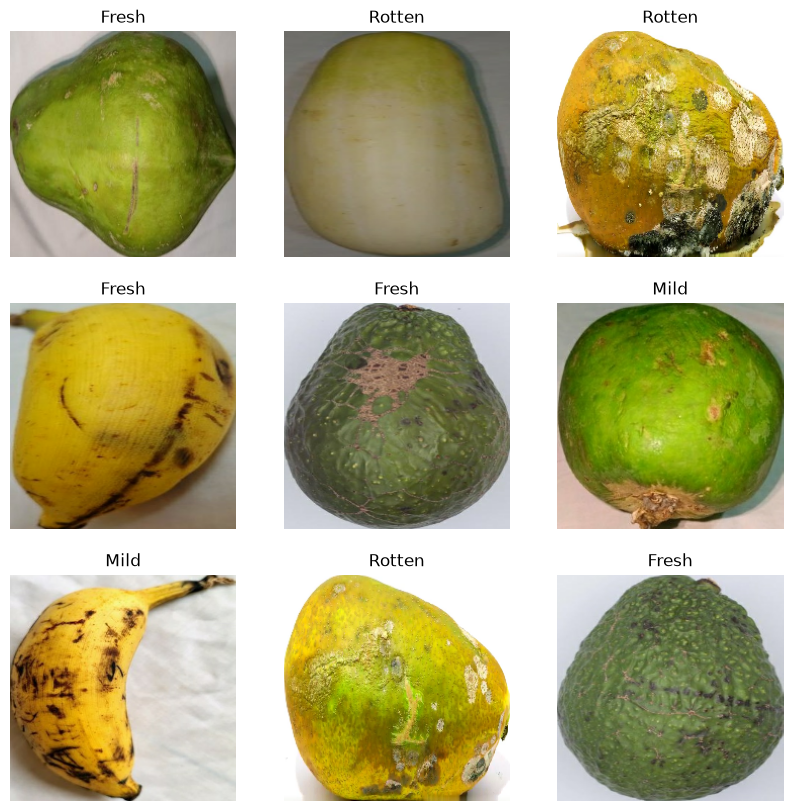

In [9]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[labels[i]])
    plt.axis("off")
plt.show()

Revisemos la cantidad de ejemplares por cada clase

In [10]:
import numpy as np
import os

class_names = train_ds.class_names

counts = []
for class_name in class_names:
    path = f"{DATA_DIR}/train/{class_name}"
    counts.append(len(os.listdir(path)))

counts = np.array(counts)

for i, j in zip(class_names, counts):
    print(f'Class {i} contains {j} examples\n')

Class Fresh contains 3901 examples

Class Mild contains 2510 examples

Class Rotten contains 2859 examples



In [11]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1),
    tf.keras.layers.RandomContrast(0.1),
], name="data_augmentation")

# Solo train: eval y test deben ver las imágenes tal como llegarán en producción.
train_ds = train_ds.map(
    lambda images, labels: (data_augmentation(images, training=True), labels),
    num_parallel_calls=tf.data.AUTOTUNE,
).prefetch(tf.data.AUTOTUNE)

W0000 00:00:1792764422.152566   23293 local_rendezvous.cc:412] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_33}}]]
	 [[GroupCrossDeviceControlEdges_0/NoOp/_32]] [type.googleapis.com/tensorflow.DerivedStatus='']


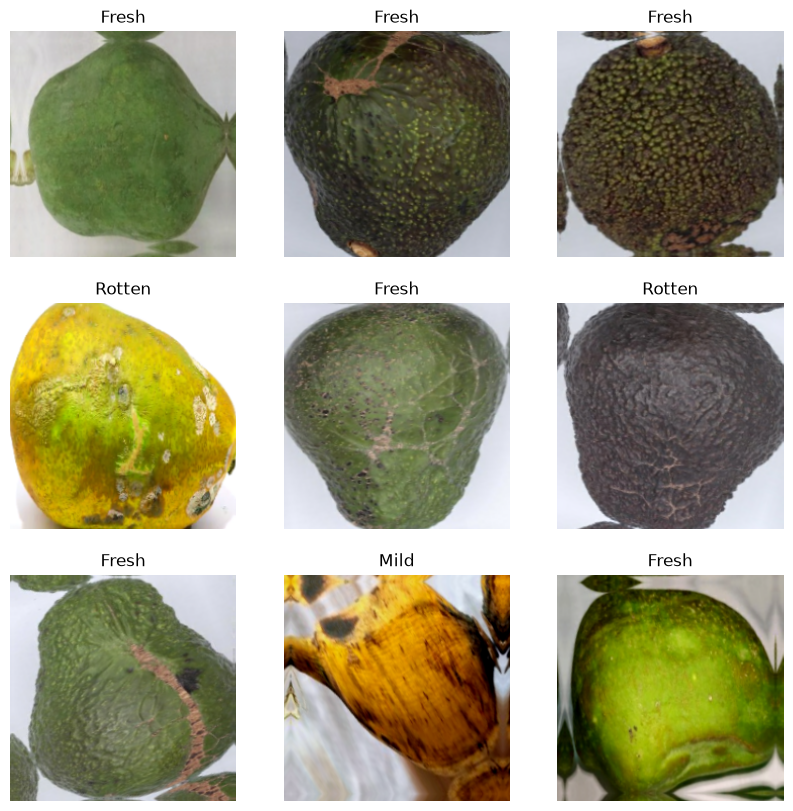

In [13]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[labels[i]])
    plt.axis("off")
plt.show()

In [14]:
class_weights = {
    i: sum(counts) / (len(counts) * counts[i])
    for i in range(len(counts))
}

print(class_weights)

{0: np.float64(0.7921045885670341), 1: np.float64(1.2310756972111554), 2: np.float64(1.080797481636936)}


In [15]:
for split in ["train", "eval", "test"]:
    counts = {name: len(list((DATA_DIR / split / name).iterdir())) for name in CLASS_NAMES}
    print(f"{split}: {sum(counts.values())} imágenes {counts}")

train: 9270 imágenes {'Fresh': 3901, 'Mild': 2510, 'Rotten': 2859}
eval: 530 imágenes {'Fresh': 222, 'Mild': 143, 'Rotten': 165}
test: 1051 imágenes {'Fresh': 421, 'Mild': 299, 'Rotten': 331}


In [16]:
base_model = tf.keras.applications.MobileNetV2(input_shape=(224,224,3), include_top=False, weights='imagenet')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [17]:
base_model.trainable = False

In [18]:
inputs = tf.keras.Input(shape=(None,None,3))

x = tf.keras.layers.Resizing(224, 224)(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(3, activation='softmax')(x)

transfer_learning_model = tf.keras.Model(inputs, outputs)

In [19]:
transfer_learning_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

transfer_learning_model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [21]:
epochs = 50

historial_tf_model = transfer_learning_model.fit(
    train_ds,
    epochs = epochs,
    validation_data = test_ds,
    class_weight=class_weights
)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792764466.889688   22646 service.cc:153] XLA service 0x73585805cf00 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792764466.889724   22646 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-80GB, Compute Capability 8.0 (Driver: 13.2.0; Runtime: 12.8.0; Toolkit: 12.5.0; DNN: 9.10.2)
I0000 00:00:1792764467.053819   22646 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792764474.229000   22646 cuda_dnn.cc:461] Loaded cuDNN version 91002
I0000 00:00:1792764474.468303   22646 dot_merger.cc:481] Merging Dots in computation:

144/145 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6330 - loss: 0.7987

I0000 00:00:1792764498.435378   22643 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8453__.120
E0000 00:00:1792764500.502718   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764500.687830   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764501.150517   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764502.576422   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764503.919350   22643 cuda_timer.cc:87] Delay kernel timed out

145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.6335 - loss: 0.7981

E0000 00:00:1792764527.929478   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764529.448159   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764530.597895   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764534.168113   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1792764535.410987   22643 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000

145/145 ━━━━━━━━━━━━━━━━━━━━ 76s 307ms/step - accuracy: 0.6335 - loss: 0.7981 - val_accuracy: 0.7212 - val_loss: 0.6265
Epoch 2/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step - accuracy: 0.7547 - loss: 0.5724 - val_accuracy: 0.7583 - val_loss: 0.5343
Epoch 3/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.7802 - loss: 0.5276 - val_accuracy: 0.7774 - val_loss: 0.4969
Epoch 4/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.7942 - loss: 0.4854 - val_accuracy: 0.7954 - val_loss: 0.4697
Epoch 5/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.8046 - loss: 0.4673 - val_accuracy: 0.8011 - val_loss: 0.4465
Epoch 6/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.8126 - loss: 0.4557 - val_accuracy: 0.8088 - val_loss: 0.4411
Epoch 7/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.8113 - loss: 0.4525 - val_accuracy: 0.7954 - val_loss: 0.4448
Epoch 8/50
145/145 ━━━━━━━━━━━━━━━━━━━━ 10s 62ms/step - accuracy: 0.8124 - loss: 0.4527 - val_accura

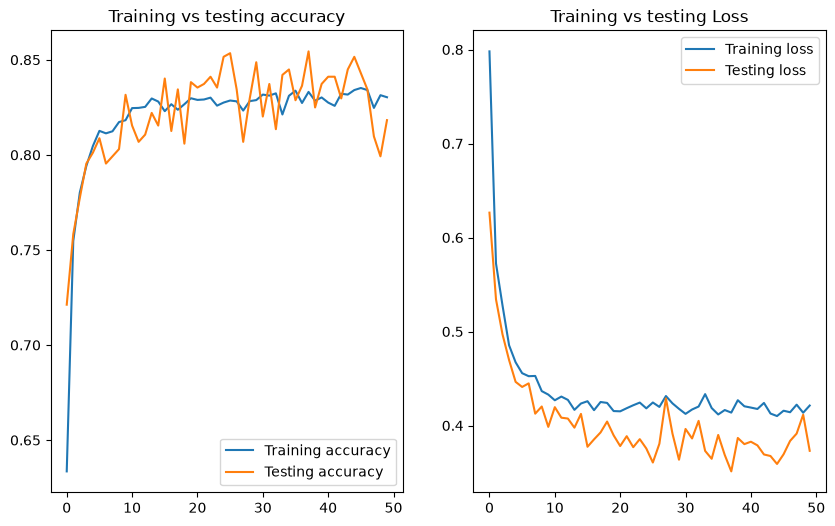

In [22]:
acc = historial_tf_model.history['accuracy']
val_acc = historial_tf_model.history['val_accuracy']

loss = historial_tf_model.history['loss']
val_loss = historial_tf_model.history['val_loss']

epochs_range = range(50)

plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
plt.plot(epochs_range, acc, label='Training accuracy')
plt.plot(epochs_range, val_acc, label='Testing accuracy')
plt.legend(loc='lower right')
plt.title('Training vs testing accuracy')

plt.subplot(1,2,2)
plt.plot(epochs_range, loss, label='Training loss')
plt.plot(epochs_range, val_loss, label='Testing loss')
plt.legend(loc='upper right')
plt.title('Training vs testing Loss')
plt.show()

In [30]:
from tensorflow.keras.preprocessing import image

def predict(path, class_names):
    
    img = image.load_img(path, color_mode='rgb')
    
    
    img_array = image.img_to_array(img)
    
    img_array = np.expand_dims(img_array, axis=0)

    predictions = transfer_learning_model.predict(img_array)
    index = np.argmax(predictions[0])
    trust = 100 * np.max(predictions[0])
    
    print(f"Prediction: {class_names[index]} | Trust: {trust:.2f}%")
    return class_names[index]

In [36]:
!ls workspace/agrotrace/crops/eval/Rotten/

 Avocado_T10_d19_227_b_5.jpg
 Avocado_T10_d22_129_b_5.jpg
 Avocado_T10_d22_395_a_5.jpg
 Avocado_T10_d23_129_b_5.jpg
 Avocado_T10_d23_349_b_5.jpg
 Avocado_T10_d23_376_b_5.jpg
 Avocado_T10_d24_125_a_5.jpg
 Avocado_T10_d24_152_b_5.jpg
 Avocado_T10_d25_234_a_5.jpg
 Avocado_T10_d25_355_b_5.jpg
 Avocado_T10_d26_294_b_5.jpg
 Avocado_T10_d26_475_b_5.jpg
 Avocado_T20_d10_228_a_5.jpg
 Avocado_T20_d10_324_b_5.jpg
 Avocado_Tam_d10_340_a_5.jpg
 Avocado_Tam_d10_362_a_5.jpg
 Avocado_Tam_d10_437_b_5.jpg
 Avocado_Tam_d11_374_a_5.jpg
 BananaDB_Image1261.png
 BananaDB_Image779.png
 BananaDB_Image891.png
 BananaDB_Image899.png
 BananaDB_Image949.png
 BananaDB_Image999.png
 BananaDB_agrifresh_IMG_20251109_111926547_HDR_AE.jpg
 BananaDB_agrifresh_IMG_20251109_112010685_HDR_AE.jpg
 BananaDB_agrifresh_IMG_20251125_210212295_HDR.jpg
 CucumberQ_Image151.png
 CucumberQ_Image155.png
 CucumberQ_Image159.png
 CucumberQ_Image195.png
 CucumberQ_Image203.png
 CucumberQ_Image87.png
 CucumberQ_Image9.png
 CucumberQ_Imag

In [ ]:
# Debe retornar Fresh
path = "/workspace/agrotrace/crops/eval/Fresh/Avocado_T10_d05_012_b_2.jpg"
predict(path, class_names)

E0000 00:00:1792765284.338304   22639 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step
Prediction: Fresh | Trust: 99.41%


'Fresh'

In [ ]:
# Debe retornar Mild
path = "/workspace/agrotrace/crops/eval/Mild/tomatoQ_agrifresh_aug_44_IMG_20251118_170507501_HDR.jpg"
predict(path, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Prediction: Mild | Trust: 95.19%


'Mild'

In [ ]:
# Debe retornar Rotten
path = "/workspace/agrotrace/crops/eval/Rotten/Avocado_T10_d23_376_b_5.jpg"
predict(path, class_names)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Prediction: Rotten | Trust: 74.91%


'Rotten'

In [40]:
transfer_learning_model.export('tf_saved_model')

INFO:tensorflow:Assets written to: tf_saved_model/assets


INFO:tensorflow:Assets written to: tf_saved_model/assets


Saved artifact at 'tf_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, None, None, 3), dtype=tf.float32, name='keras_tensor_160')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  126847984544336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984543568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984542224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984542800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984542992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984543376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984538768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984541264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984544912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  126847984540112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1268479845

In [42]:
%pip install git+https://github.com/onnx/tensorflow-onnx

  Cloning https://github.com/onnx/tensorflow-onnx to /tmp/pip-req-build-b9susda3
  Running command git clone --filter=blob:none --quiet https://github.com/onnx/tensorflow-onnx /tmp/pip-req-build-b9susda3
  Resolved https://github.com/onnx/tensorflow-onnx to commit f77f5acf9be6066ea3345887119204453d1da32e
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [46]:
!ls

NGC-DL-CONTAINER-LICENSE  jupyter.log	     proc		 sys
bin			  lib		     root		 tf_saved_model
bin.usr-is-merged	  lib.usr-is-merged  run		 tmp
boot			  lib64		     sbin		 usr
dev			  media		     sbin.usr-is-merged  var
etc			  mnt		     srv		 workspace
home			  opt		     start.sh


In [47]:
!python3 -m tf2onnx.convert --saved-model /tf_saved_model/ --output /workspace/agrotrace/tf_model_mobilenetv2.onnx

I0000 00:00:1792765730.571342   55760 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792765733.065624   55760 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 847 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:bd:00.0, compute capability: 8.0
2026-10-23 14:28:53,081 - WARNING - '--tag' not specified for saved_model. Using --tag serve
2026-10-23 14:28:54,309 - INFO - Signatures found in model: [serve,serving_default].
2026-10-23 14:28:54,309 - WARNING - '--signature_def' not specified, using first signature: serve
2026-10-23 14:28:54,310 - INFO - Output names: ['output_0']
I0000 00:00:1792765734.321508   55760 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 1
I0000 00:00: